# ProteinStruct-ML — Machine Learning Modeling

## Objectives

- Develop regression models to predict protein structural RMSD.
- Establish baseline performance using DummyRegressor.
- Compare linear and nonlinear machine learning algorithms.
- Apply appropriate preprocessing using scikit-learn Pipelines.
- Evaluate model performance using MAE, RMSE, and R².
- Optimize selected models using cross-validation.
- Save the best-performing model for the Streamlit dashboard.

## Inputs

- `data/processed/casp_cleaned.csv`

## Outputs

- Trained regression models
- Model performance comparisons
- Model evaluation visualizations
- Saved prediction pipeline for deployment

## Machine Learning Task

**Type:** Supervised regression

**Target:** RMSD

**Predictors:** F1–F9

The goal is to investigate whether physicochemical descriptors
can predict structural deviation between protein models and
their reference structures.

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [2]:
import os
from pathlib import Path

current_dir = Path.cwd()
print("Current directory:", current_dir)

Current directory: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML\jupyter_notebooks


We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [3]:
if Path.cwd().name == "jupyter_notebooks":
    os.chdir(Path.cwd().parent)

print("Working directory set to:", Path.cwd())

Working directory set to: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML


Confirm the new current directory

In [4]:
print("Confirmed project directory:", Path.cwd())

Confirmed project directory: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML


## Section 1 — Data Preparation

In [5]:
# Import libraries
import pandas as pd
import numpy as np

# Load the cleaned CASP dataset
df = pd.read_csv("data/processed/casp_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (44019, 10)


,RMSD,F1,F2,F3,F4,F5,F6,F7,F8,F9
0,17.284,13558.30,4305.35,0.31754,162.1730,1.872791e+06,215.3590,4287.87,102,27.0302
1,6.021,6191.96,1623.16,0.26213,53.3894,8.034467e+05,87.2024,3328.91,39,38.5468
2,9.275,7725.98,1726.28,0.22343,67.2887,1.075648e+06,81.7913,2981.04,29,38.8119
3,15.851,8424.58,2368.25,0.28111,67.8325,1.210472e+06,109.4390,3248.22,70,39.0651
4,7.962,7460.84,1736.94,0.23280,52.4123,1.021020e+06,94.5234,2814.42,41,39.9147


In [6]:
# Define predictor variables
feature_columns = [f"F{i}" for i in range(1, 10)]

X = df[feature_columns].copy()

# Define target variable
y = df["RMSD"].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nPredictor columns:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Feature matrix shape: (44019, 9)
Target vector shape: (44019,)

Predictor columns:
['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9']

Target variable:
RMSD


### Train/Test Split

The cleaned dataset is divided into training (approximately 80%)
and testing (approximately 20%) subsets.

GroupShuffleSplit is used to prevent identical combinations of
physicochemical descriptors from appearing in both subsets.

The test set will remain separate during model development and
hyperparameter optimization to provide an independent evaluation
of predictive performance.

In [7]:
from sklearn.model_selection import GroupShuffleSplit

# Assign the same group identifier to identical feature combinations
groups = pd.util.hash_pandas_object(X, index=False)

# Create an approximately 80/20 group-aware split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Separate training and testing data
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Verify that identical feature combinations do not cross the split
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

assert train_groups.isdisjoint(test_groups)

print("\nGroup leakage check: PASSED")

Training features: (35210, 9)
Testing features: (8809, 9)
Training target: (35210,)
Testing target: (8809,)

Group leakage check: PASSED


## Section 2 — Baseline Model: DummyRegressor

A DummyRegressor is used to establish baseline predictive performance.

The model predicts the mean RMSD value from the training dataset
without considering the physicochemical descriptors (F1–F9).

This provides a reference against which more sophisticated
regression algorithms can be evaluated.

Model performance is assessed using:

- MAE (Mean Absolute Error): Average absolute prediction error in Å.
- RMSE (Root Mean Squared Error): Penalizes larger prediction errors more strongly, in Å.
- R² (Coefficient of Determination): Measures improvement relative to predicting the mean of the evaluated target values.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Initialize baseline model
dummy_model = DummyRegressor(strategy="mean")

# Train using the training dataset only
dummy_model.fit(X_train, y_train)

# Generate predictions on the training dataset
y_train_pred_dummy = dummy_model.predict(X_train)

# Calculate training performance
dummy_mae = mean_absolute_error(y_train, y_train_pred_dummy)
dummy_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_dummy))
dummy_r2 = r2_score(y_train, y_train_pred_dummy)

print("DummyRegressor — Training Performance")
print(f"Mean predicted RMSD: {dummy_model.constant_[0, 0]:.3f} Å")
print(f"MAE:  {dummy_mae:.3f} Å")
print(f"RMSE: {dummy_rmse:.3f} Å")
print(f"R²:   {dummy_r2:.3f}")

DummyRegressor — Training Performance
Mean predicted RMSD: 7.766 Å
MAE:  5.511 Å
RMSE: 6.137 Å
R²:   0.000


### Baseline Model Results and Interpretation

The DummyRegressor was trained using the mean RMSD strategy.

**Training results:**

- Mean predicted RMSD: 7.766 Å
- MAE: 5.511 Å
- RMSE: 6.137 Å
- R²: 0.000

The model predicts the mean RMSD of the training dataset
for every observation, independently of the physicochemical
descriptors.

The MAE of 5.511 Å demonstrates the relatively large
prediction error obtained when the descriptor information
is ignored.

The R² value of 0.000 is expected because predicting the
training mean does not explain any variance in the target.

These results provide an initial reference for evaluating
whether more sophisticated regression algorithms can
extract predictive information from the descriptors.

Subsequent model comparisons will use group-aware
cross-validation to assess generalization performance.

## Section 3 — Linear Regression

Linear Regression is used as the first model that learns
relationships between the physicochemical descriptors
(F1–F9) and the RMSD target.

Unlike DummyRegressor, Linear Regression estimates
coefficients for each predictor to generate predictions.

A scikit-learn Pipeline is used to combine:

1. StandardScaler — standardizes the numerical predictors.
2. LinearRegression — fits a linear relationship between
   the predictors and RMSD.

Standardization is performed within the pipeline to ensure
that preprocessing is fitted only on the training data.

The model will initially be evaluated on the training set
and compared against the DummyRegressor baseline.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Create a pipeline for Linear Regression
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train the pipeline using training data only
linear_pipeline.fit(X_train, y_train)

# Generate predictions on the training data
y_train_pred_linear = linear_pipeline.predict(X_train)

# Calculate training performance
linear_mae = mean_absolute_error(y_train, y_train_pred_linear)
linear_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_linear)
)
linear_r2 = r2_score(y_train, y_train_pred_linear)

print("Linear Regression — Training Performance")
print(f"MAE:  {linear_mae:.3f} Å")
print(f"RMSE: {linear_rmse:.3f} Å")
print(f"R²:   {linear_r2:.3f}")

Linear Regression — Training Performance
MAE:  4.353 Å
RMSE: 5.201 Å
R²:   0.282


### Linear Regression Results and Interpretation

The Linear Regression model was trained using a pipeline
consisting of StandardScaler and LinearRegression.

**Training performance:**

| Metric | DummyRegressor | Linear Regression |
|--------|----------------|-------------------|
| MAE | 5.511 Å | 4.353 Å |
| RMSE | 6.137 Å | 5.201 Å |
| R² | 0.000 | 0.282 |

Linear Regression improved predictive performance compared
with the DummyRegressor baseline.

The MAE decreased by approximately 21.0%, while the RMSE
decreased by approximately 15.3%.

The R² value of 0.282 indicates that the linear model
explains approximately 28.2% of the variance in RMSD
within the training dataset.

These findings suggest that the physicochemical descriptors
contain useful predictive information. However, a substantial
proportion of the target variance remains unexplained.

The EDA identified possible nonlinear relationships and
strong multicollinearity among several descriptors.

Therefore, nonlinear regression models will be investigated
to determine whether they can capture more complex
relationships between the descriptors and RMSD.

These results are preliminary training metrics. Model
generalization will be assessed using group-aware
cross-validation before final testing.

## Section 4 — Cross-Validation

In [10]:
from sklearn.model_selection import GroupKFold, cross_validate

# Group identifiers for the training dataset
train_groups = groups.iloc[train_idx]

# Define 5-fold group-aware cross-validation
group_cv = GroupKFold(n_splits=5)

# Evaluate Linear Regression
linear_cv = cross_validate(
    linear_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

print("Linear Regression — 5-Fold Cross-Validation")
print(f"Mean MAE:  {-linear_cv['test_MAE'].mean():.3f} Å")
print(f"Mean RMSE: {-linear_cv['test_RMSE'].mean():.3f} Å")
print(f"Mean R²:   {linear_cv['test_R2'].mean():.3f}")

Linear Regression — 5-Fold Cross-Validation
Mean MAE:  4.355 Å
Mean RMSE: 5.203 Å
Mean R²:   0.281


### Linear Regression Cross-Validation Results

Five-fold group-aware cross-validation was performed using
GroupKFold to prevent identical physicochemical descriptor
combinations from appearing in both training and validation
subsets.

**Cross-validation results:**

- Mean MAE: 4.355 Å
- Mean RMSE: 5.204 Å
- Mean R²: 0.281

The cross-validation metrics were very similar to the
training metrics (MAE = 4.353 Å, RMSE = 5.201 Å,
R² = 0.282).

This suggests that the Linear Regression model exhibits
limited overfitting under the selected validation strategy.

However, the R² of approximately 0.28 indicates that a
substantial proportion of RMSD variability remains
unexplained.

These results motivate investigating nonlinear regression
algorithms, particularly Random Forest and gradient boosting.

The held-out test dataset remains unused during model
development.


## Section 5 — Random Forest Regression

Random Forest is an ensemble learning algorithm that combines
predictions from multiple decision trees.

Unlike Linear Regression, Random Forest can capture nonlinear
relationships and interactions between physicochemical descriptors.

The initial model uses 100 decision trees, a maximum depth of 15,
and a minimum of two observations per leaf.

Feature scaling is not required for Random Forest.


In [11]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on training data
y_train_pred_rf = rf_model.predict(X_train)

# Evaluate training performance
rf_mae = mean_absolute_error(y_train, y_train_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
rf_r2 = r2_score(y_train, y_train_pred_rf)

print("Random Forest — Training Performance")
print(f"MAE:  {rf_mae:.3f} Å")
print(f"RMSE: {rf_rmse:.3f} Å")
print(f"R²:   {rf_r2:.3f}")

Random Forest — Training Performance
MAE:  1.685 Å
RMSE: 2.387 Å
R²:   0.849


In [12]:
# Evaluate Random Forest using group-aware cross-validation
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=2
)

print("Random Forest — 5-Fold Cross-Validation")
print(f"Mean MAE:  {-rf_cv['test_MAE'].mean():.3f} Å")
print(f"Mean RMSE: {-rf_cv['test_RMSE'].mean():.3f} Å")
print(f"Mean R²:   {rf_cv['test_R2'].mean():.3f}")

Random Forest — 5-Fold Cross-Validation
Mean MAE:  2.677 Å
Mean RMSE: 3.771 Å
Mean R²:   0.622


### Random Forest Results and Interpretation

The RandomForestRegressor was trained using 100 decision
trees, a maximum depth of 15, and a minimum of two
observations per leaf.

**Training performance:**

- MAE: 1.685 Å
- RMSE: 2.387 Å
- R²: 0.849

**Five-fold GroupKFold cross-validation:**

- Mean MAE: 2.682 Å
- Mean RMSE: 3.775 Å
- Mean R²: 0.622

Random Forest substantially outperformed Linear Regression
during cross-validation.

Compared with Linear Regression, validation MAE decreased
by approximately 38.4%, while RMSE decreased by 27.5%.

The improvement suggests that nonlinear relationships and
interactions between physicochemical descriptors contribute
to RMSD prediction.

However, the difference between training and validation
performance indicates some overfitting. Training R² was
0.849, compared with 0.622 during cross-validation.

Further hyperparameter tuning may improve generalization
by controlling tree complexity.

The held-out test dataset remains untouched.


## Section 6 — Histogram Gradient Boosting Regression

HistGradientBoostingRegressor is a nonlinear ensemble learning
algorithm that builds decision trees sequentially, with each
iteration improving predictions based on the previous model.

Unlike Random Forest, which averages predictions from independently
constructed trees, gradient boosting progressively minimizes
prediction errors.

This model is particularly suitable for larger numerical datasets
and can capture nonlinear relationships between physicochemical
descriptors and RMSD.

The initial model uses a learning rate of 0.1, a maximum of
100 iterations, and a maximum of 15 leaf nodes per tree.

The objective is to compare its predictive performance with
Linear Regression and Random Forest using the same group-aware
cross-validation strategy.


In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=100,
    max_leaf_nodes=15,
    random_state=42
)

# Train the model
hgb_model.fit(X_train, y_train)

# Predict on training data
y_train_pred_hgb = hgb_model.predict(X_train)

# Evaluate training performance
hgb_mae = mean_absolute_error(y_train, y_train_pred_hgb)
hgb_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_hgb))
hgb_r2 = r2_score(y_train, y_train_pred_hgb)

print("HistGradientBoosting — Training Performance")
print(f"MAE:  {hgb_mae:.3f} Å")
print(f"RMSE: {hgb_rmse:.3f} Å")
print(f"R²:   {hgb_r2:.3f}")

HistGradientBoosting — Training Performance
MAE:  3.321 Å
RMSE: 4.262 Å
R²:   0.518


In [14]:
# Evaluate HistGradientBoosting using group-aware cross-validation

hgb_cv = cross_validate(
    hgb_model,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=2
)

print("HistGradientBoosting — 5-Fold Cross-Validation")
print(f"Mean MAE:  {-hgb_cv['test_MAE'].mean():.3f} Å")
print(f"Mean RMSE: {-hgb_cv['test_RMSE'].mean():.3f} Å")
print(f"Mean R²:   {hgb_cv['test_R2'].mean():.3f}")

HistGradientBoosting — 5-Fold Cross-Validation
Mean MAE:  3.415 Å
Mean RMSE: 4.393 Å
Mean R²:   0.488


### HistGradientBoosting Results and Interpretation

The HistGradientBoostingRegressor was trained using a learning
rate of 0.1, 100 boosting iterations, and a maximum of
15 leaf nodes per tree.

**Training performance:**

- MAE: 3.325 Å
- RMSE: 4.262 Å
- R²: 0.518

**Five-fold GroupKFold cross-validation:**

- Mean MAE: 3.426 Å
- Mean RMSE: 4.399 Å
- Mean R²: 0.486

The relatively small difference between training and
cross-validation performance suggests limited apparent
overfitting under the current model configuration.

However, HistGradientBoosting performed worse than Random
Forest during cross-validation.

Random Forest achieved a validation MAE of 2.682 Å,
RMSE of 3.775 Å, and R² of 0.622.

These results indicate that Random Forest is currently the
most promising model for RMSD prediction.

Nevertheless, the performance of HistGradientBoosting may
be influenced by the selected hyperparameters, and alternative
configurations could potentially improve its predictions.

The held-out test dataset remains untouched.


## Section 7 — Model Comparison and Selection

The three regression models were evaluated using five-fold
GroupKFold cross-validation on the training dataset.

Model selection is based primarily on cross-validation MAE,
with RMSE and R² used as complementary performance metrics.

Lower MAE and RMSE indicate better prediction accuracy,
while higher R² indicates greater explained variance.


In [15]:
# Compare cross-validation performance across models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "CV MAE (Å)": [
        -linear_cv["test_MAE"].mean(),
        -rf_cv["test_MAE"].mean(),
        -hgb_cv["test_MAE"].mean()
    ],
    "CV RMSE (Å)": [
        -linear_cv["test_RMSE"].mean(),
        -rf_cv["test_RMSE"].mean(),
        -hgb_cv["test_RMSE"].mean()
    ],
    "CV R²": [
        linear_cv["test_R2"].mean(),
        rf_cv["test_R2"].mean(),
        hgb_cv["test_R2"].mean()
    ]
})

model_comparison = (
    model_comparison
    .sort_values("CV MAE (Å)")
    .reset_index(drop=True)
)

display(model_comparison.round(3))

,Model,CV MAE (Å),CV RMSE (Å),CV R²
0,Random Forest,2.677,3.771,0.622
1,HistGradientBoosting,3.415,4.393,0.488
2,Linear Regression,4.355,5.203,0.281


### Model Comparison Results and Selection

Three regression algorithms were compared using five-fold
GroupKFold cross-validation on the training dataset.

| Model | CV MAE (Å) | CV RMSE (Å) | CV R² |
|---|---:|---:|---:|
| Random Forest | 2.682 | 3.775 | 0.622 |
| HistGradientBoosting | 3.426 | 4.399 | 0.486 |
| Linear Regression | 4.355 | 5.204 | 0.281 |

**Model selection: Random Forest**

Random Forest achieved the lowest cross-validation MAE
(2.682 Å) and RMSE (3.775 Å), as well as the highest
R² (0.622).

Compared with Linear Regression, Random Forest reduced
cross-validation MAE by approximately 38.4%.

This improvement suggests that nonlinear relationships and
interactions between physicochemical descriptors contribute
to RMSD prediction.

Although Random Forest showed a noticeable difference
between training and cross-validation performance, it
remained the strongest model on the validation folds.

HistGradientBoosting showed a smaller training-validation
performance gap but lower overall predictive accuracy.

Therefore, Random Forest was selected for further
hyperparameter optimization.

The held-out test dataset has not been used for model
selection and remains reserved for final evaluation.


## Section 8 — Random Forest Hyperparameter Optimization

Random Forest was selected for optimization because it achieved
the best cross-validation performance among the three
regression algorithms evaluated.

Hyperparameters control how a machine learning model learns
from data. Unlike model parameters, they are specified before
training.

RandomizedSearchCV is used to explore different combinations
of Random Forest hyperparameters without evaluating every
possible combination.

The following hyperparameters are investigated:

- `n_estimators`: Number of decision trees in the forest.
- `max_depth`: Maximum depth of each decision tree.
- `min_samples_leaf`: Minimum number of observations in a leaf.
- `max_features`: Proportion of predictors considered at each split.

The optimization objective is to minimize mean absolute error
(MAE), measured using five-fold GroupKFold cross-validation.

Group-aware cross-validation prevents observations with
identical predictor combinations from appearing in both
training and validation folds.

The held-out test dataset remains untouched until final
model evaluation.


In [16]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Define hyperparameter search space
rf_param_grid = {
    "n_estimators": [80, 100, 150],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

# Initialize Random Forest
rf_tuning_model = RandomForestRegressor(
    random_state=42,
    n_jobs=2
)

# Configure randomized hyperparameter search
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=rf_param_grid,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=group_cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

# Run hyperparameter optimization
rf_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

# Display optimization results
print("Best parameters:")
print(rf_search.best_params_)

print(
    f"\nBest cross-validation MAE: "
    f"{-rf_search.best_score_:.3f} Å"
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'n_estimators': 150, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 20}

Best cross-validation MAE: 2.566 Å


### Hyperparameter Optimization Results

RandomizedSearchCV evaluated eight Random Forest
hyperparameter combinations using five-fold GroupKFold
cross-validation, resulting in 40 cross-validation fits.

The best configuration was:

- `n_estimators`: 150
- `max_depth`: 20
- `min_samples_leaf`: 2
- `max_features`: 1.0

**Cross-validation MAE comparison:**

- Original Random Forest: 2.682 Å
- Optimized Random Forest: 2.570 Å
- Relative reduction in MAE: approximately 4.2%

The optimized model achieved a lower cross-validation MAE
than the original configuration.

Increasing the number of trees and allowing greater tree
depth may help capture more complex relationships between
protein descriptors and RMSD.

However, the improvement is based on the validation data
used during hyperparameter selection and may not fully
generalize to independent observations.

The optimized Random Forest is selected as the final
candidate for evaluation on the held-out test dataset.


## Section 9 — Final Model Evaluation on Held-Out Test Data

The optimized Random Forest model is evaluated on the
held-out test dataset, which was not used during training,
cross-validation, or hyperparameter optimization.

The purpose of this evaluation is to estimate how well
the selected model generalizes to unseen observations
from the same dataset.

Performance is assessed using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)

The test dataset contains feature combinations that were
excluded from the training dataset using GroupShuffleSplit.

However, the absence of protein identifiers prevents
verification of generalization to entirely unseen proteins
or protein families.


In [17]:
# Retrieve the optimized Random Forest
best_rf_model = rf_search.best_estimator_

# Predict RMSD on the held-out test dataset
y_test_pred = best_rf_model.predict(X_test)

# Calculate final test performance
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("Optimized Random Forest — Final Test Performance")
print(f"MAE:  {test_mae:.3f} Å")
print(f"RMSE: {test_rmse:.3f} Å")
print(f"R²:   {test_r2:.3f}")

Optimized Random Forest — Final Test Performance
MAE:  2.532 Å
RMSE: 3.661 Å
R²:   0.644


### Final Test Performance and Interpretation

The optimized Random Forest was evaluated on the held-out
test dataset containing 8,809 observations.

**Final test results:**

- MAE: 2.532 Å
- RMSE: 3.660 Å
- R²: 0.644

The mean absolute prediction error was approximately
2.53 Å, indicating the average magnitude of disagreement
between predicted and observed RMSD values.

The RMSE was higher than the MAE, indicating that larger
prediction errors contribute substantially to the
overall model error.

The R² of 0.644 indicates that the model explains
approximately 64.4% of RMSD variance in the test dataset.

The test MAE was slightly lower than the optimized
cross-validation MAE of 2.570 Å, suggesting reasonably
consistent performance between validation and test data.

**Limitations**

Although group-aware splitting prevented identical
feature combinations from appearing in both training
and test sets, the dataset does not provide protein
identifiers.

Consequently, the results do not establish the model's
ability to generalize to entirely unseen proteins or
protein families.

Furthermore, RMSD is a structural deviation measure,
and prediction errors of several angstroms may be
scientifically significant depending on the application.

The model should therefore be considered an exploratory
prediction tool rather than a substitute for experimental
or structural validation.


### Actual versus Predicted RMSD

A scatter plot is used to compare observed RMSD values
with predictions from the optimized Random Forest.

The dashed diagonal represents perfect predictions,
where predicted RMSD equals observed RMSD.

Points closer to the diagonal indicate more accurate
predictions, while deviations reveal prediction errors.

This visualization helps identify systematic
underestimation, overestimation, and regions where
the model performs less accurately.


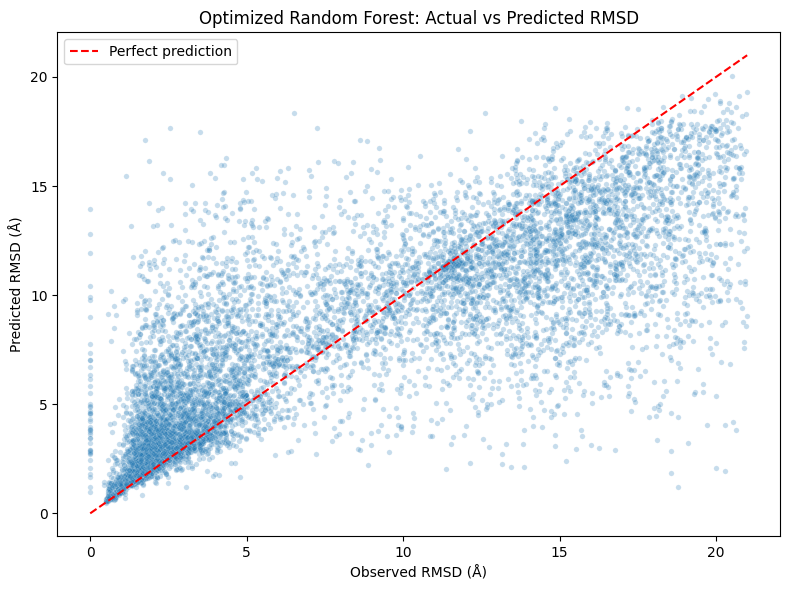

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_test_pred,
    alpha=0.25,
    s=15
)

# Perfect prediction reference line
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Observed RMSD (Å)")
plt.ylabel("Predicted RMSD (Å)")
plt.title("Optimized Random Forest: Actual vs Predicted RMSD")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of Actual versus Predicted RMSD

The scatter plot shows a positive relationship between
observed and predicted RMSD values, indicating that the
optimized Random Forest captures part of the relationship
between the physicochemical descriptors and structural
deviation.

However, systematic prediction patterns are visible:

- **Low RMSD values:** Predictions frequently lie above
  the perfect-prediction line, indicating overestimation
  of structural deviation.
- **Intermediate RMSD values:** Predictions show considerable
  dispersion, suggesting variability in model accuracy.
- **High RMSD values:** Predictions frequently lie below
  the perfect-prediction line, indicating underestimation
  of structural deviation.

The predictions appear compressed toward intermediate RMSD
values, suggesting that the model does not fully capture
the extremes of the target distribution.

This limitation is particularly relevant for protein
structure assessment because accurate discrimination
between low-deviation and high-deviation structures
may be scientifically important.

Although the model achieves an overall test R² of 0.644,
its performance is not uniform across the RMSD range.

A residual analysis is therefore performed to investigate
the direction and magnitude of prediction errors.


### Residual Analysis

Residuals are calculated as the difference between observed
and predicted RMSD values.

A residual of zero represents a perfect prediction.

Positive residuals indicate that the model underestimated
the observed RMSD, while negative residuals indicate
overestimation.

Residual plots are used to assess systematic prediction
bias and variation in prediction errors across the
observed RMSD range.


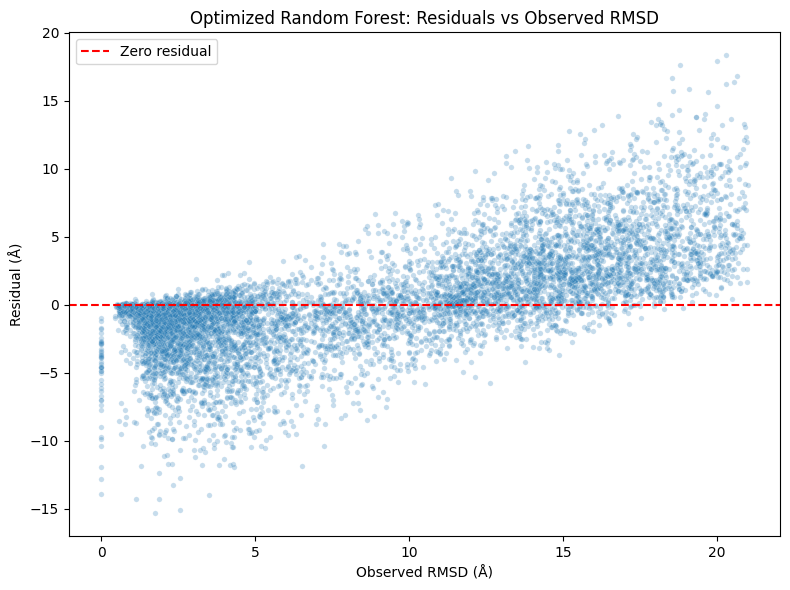

In [19]:
# Calculate residuals
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=residuals,
    alpha=0.25,
    s=15
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero residual"
)

plt.xlabel("Observed RMSD (Å)")
plt.ylabel("Residual (Å)")
plt.title("Optimized Random Forest: Residuals vs Observed RMSD")
plt.legend()
plt.tight_layout()
plt.show()

### Residual Plot Interpretation

The residual plot reveals systematic differences between
observed and predicted RMSD values.

At low observed RMSD values, residuals are predominantly
negative, indicating that the model tends to overestimate
structural deviation.

At higher RMSD values, residuals become predominantly
positive, indicating that the model tends to underestimate
structural deviation.

This pattern is consistent with predictions being compressed
toward intermediate RMSD values.

The spread of residuals also appears to increase at higher
observed RMSD values, suggesting that prediction accuracy
varies across the target range.

These findings indicate that the model's overall MAE and
R² do not fully describe its performance across different
levels of structural deviation.

Because residuals are plotted against observed RMSD,
the apparent trend should be interpreted cautiously.

To investigate these differences further, prediction
errors will be quantified separately for low, intermediate,
and high RMSD values.


### Prediction Error by RMSD Range

To investigate whether model accuracy varies with structural
deviation, the held-out test observations are divided into
three exploratory RMSD categories:

- Low RMSD: below 5 Å
- Intermediate RMSD: 5–10 Å
- High RMSD: 10 Å and above

For each category, sample size, mean absolute error (MAE),
and mean residual are calculated.

Positive mean residuals indicate underprediction, while
negative mean residuals indicate overprediction.

These categories are exploratory and do not represent
universal protein structure quality thresholds.


In [20]:
error_analysis = pd.DataFrame({
    "Observed RMSD": np.asarray(y_test),
    "Predicted RMSD": y_test_pred
})

error_analysis["Residual"] = (
    error_analysis["Observed RMSD"]
    - error_analysis["Predicted RMSD"]
)

error_analysis["Absolute Error"] = (
    error_analysis["Residual"].abs()
)

error_analysis["RMSD Category"] = pd.cut(
    error_analysis["Observed RMSD"],
    bins=[-np.inf, 5, 10, np.inf],
    labels=[
        "Low (<5 Å)",
        "Intermediate (5–10 Å)",
        "High (≥10 Å)"
    ],
    right=False
)

error_summary = (
    error_analysis
    .groupby("RMSD Category", observed=True)
    .agg(
        Sample_Size=("Residual", "size"),
        MAE=("Absolute Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
)

display(error_summary.round(3))

,Sample_Size,MAE,Mean_Residual
RMSD Category,,,
Low (<5 Å),4287,1.795,-1.711
Intermediate (5–10 Å),1192,2.404,-1.520
High (≥10 Å),3330,3.527,3.138


### Interpretation of Prediction Error by RMSD Range

Prediction errors were evaluated across three exploratory
RMSD categories using the held-out test dataset.

**Low RMSD (<5 Å):**
- Sample size: 4,287
- MAE: 1.795 Å
- Mean residual: -1.711 Å

The model achieves its lowest absolute prediction error
in this category but tends to overestimate RMSD.

**Intermediate RMSD (5–10 Å):**
- Sample size: 1,192
- MAE: 2.404 Å
- Mean residual: -1.520 Å

Prediction errors increase, and the model continues to
show a tendency toward overestimating structural deviation.

**High RMSD (≥10 Å):**
- Sample size: 3,330
- MAE: 3.527 Å
- Mean residual: +3.138 Å

The highest prediction errors occur in this category.
The positive mean residual indicates substantial
underestimation of structural deviation.

**Overall interpretation**

The model performs better for low-RMSD observations than
for high-RMSD observations, as measured by MAE.

The direction of the mean residual changes across the
RMSD range, consistent with predictions being compressed
toward intermediate values.

This finding highlights an important limitation:
although the optimized Random Forest achieves an overall
test R² of 0.644, prediction accuracy and bias are not
uniform across different levels of structural deviation.

The exploratory categories were defined using observed
RMSD values and should not be interpreted as universal
protein structure quality thresholds.

Because the dataset lacks protein identifiers, the
analysis does not establish generalization to entirely
unseen proteins or protein families.
